<a href="https://colab.research.google.com/github/AviramNisimyan/BBPM/blob/main/Deep_Speckle_DiT_Pixel_X0_SpeckleTokens_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Deep Speckle — DiT in pixel space, Speckle through attention, unseen diffuser held out

**The experiment.** Direction 1 (the Transformer inside the diffusion model reads the whole Speckle
globally at every denoising step), tested for **generalisation to a diffuser that was never seen in
training**. Training uses diffusers D1–D3 only. D4 is held out completely.

**Model: unchanged.** The official Meta `DiT` class and `diffusion.create_diffusion`
(https://github.com/facebookresearch/DiT) are imported, not re-implemented. No VAE, x0-prediction, DiT-S,
patch 16, Speckle patch tokens appended to the image tokens (attention) and a pooled Speckle vector added
to the timestep embedding (adaLN-Zero), AdamW 1e-4, batch 8, EMA 0.9999, 100,000 updates, same seed.
Cells 4, 6, 7 and 8 (preprocessing, model, sampler, sanity test) are exactly the cells of the previous version.

**What changed in this version of the notebook**

| | Previous version (results in `DiT_Pixel_X0_SpeckleTokens`) | This version (results in `DiT_Pixel_X0_SpeckleTokens_D4HeldOut`) |
|---|---|---|
| Training data | 2,160 measurements, all four diffusers | 1,332 measurements: 444 objects x D1–D3 |
| Validation (checkpoint selection) | 240 measurements, all four diffusers | 288 measurements: 96 other objects x D1–D3 |
| Final test | the same 240 | 60 sealed objects, through D1 (known) and through D4 (unseen) |
| Loss logging | every 10,000 updates | training loss every epoch, validation loss every 2 epochs |
| Saved checkpoints | best Dice, last | best validation loss, best Dice, last |
| Saving to Drive | replace the file in place | new file name per save, copy verified by SHA-256 |

The previous version measured generalisation to unseen objects with all diffusers seen in training (the
protocol of the shared baseline). Its results stay on Drive and are not touched by this version.

The split is the same object split as the contrastive-encoder notebook (split seed 31114, same
fingerprint), so the two directions are trained and tested on exactly the same measurements.

**Preprocessing** is the supervisor's reference: 2x2 mean binning 512->256, Speckle divided by its own
maximum, target binarised with `> 0`, `x_0 = 2*mask - 1`, float32.

**D4** was looked at in older experiments, so D4 numbers are a held-out test of the diffuser, not a
blind test. No checkpoint and no hyper-parameter is chosen with D4 or with the 60 evaluation objects.

In [ ]:
#@title 1. Configuration
SEED = 42                          # same as the previous version of this notebook
SPLIT_SEED = 31114                 # do not change: same object split as the contrastive-encoder notebook
TRAIN_DIFFUSERS = ('1', '2', '3')
HELDOUT_DIFFUSER = '4'
TRAIN_OBJECT_FRACTION = .70
VALIDATION_OBJECT_FRACTION = .15

BATCH_SIZE = 8
TRAIN_STEPS = 100_000              # optimizer updates (167 per epoch)
LR = 1e-4                          # Meta DiT value, AdamW, weight decay 0
EMA_DECAY = 0.9999                 # Meta DiT value (with warm-up)
TRAIN_TIMESTEPS = 1000             # linear schedule, official create_diffusion
SAMPLE_STEPS = 50                  # DDIM steps

DIT_HIDDEN, DIT_DEPTH, DIT_HEADS = 384, 12, 6   # DiT-S
IMAGE_PATCH = 16                   # 256 image tokens
SPECKLE_PATCH = 16                 # 256 Speckle tokens
SPECKLE_ENCODER_DEPTH = 2          # global-attention layers before the DiT
USE_SPECKLE_TOKENS = True          # Speckle through the attention
USE_SPECKLE_GLOBAL = True          # Speckle next to the time embedding (adaLN-Zero)

RUN_SANITY = True                  # 4-pair overfit + Speckle-swap test
SANITY_GATE = True                 # stop before the long run if the test fails
SANITY_STEPS = 2500
SANITY_LR = 2e-4
RUN_TRAINING = True
EVAL_EVERY = 10_000                # full DDIM reconstruction on a fixed validation subset
EVAL_SUBSET = 48
VAL_LOSS_EVERY_EPOCHS = 2          # validation loss on all 288 measurements
CHECKPOINT_EVERY = 5_000           # resumable checkpoint on Drive
PROGRESS_EVERY = 500
RUN_D4_EVAL = True                 # runs after the checkpoints are fixed; D4 is never used for selection
RESULTS_NAME = 'DiT_Pixel_X0_SpeckleTokens_D4HeldOut'
REPORT_PREFIX = 'dir1_D4heldout_'

assert USE_SPECKLE_TOKENS or USE_SPECKLE_GLOBAL, 'The model needs at least one Speckle pathway'
assert 256 % IMAGE_PATCH == 0 and 256 % SPECKLE_PATCH == 0
assert TRAIN_DIFFUSERS == ('1', '2', '3') and HELDOUT_DIFFUSER == '4'
print('DiT-S | pixel space | x0-prediction | Speckle tokens | D1-D3 train, D4 held out | steps:', TRAIN_STEPS)

DiT-S | pixel space | x0-prediction | Speckle tokens | D1-D3 train, D4 held out | steps: 100000


In [ ]:
#@title 2. Install dependencies
%pip -q install 'timm==0.9.16' 'scikit-image>=0.24' 'pandas>=2.1'

In [ ]:
#@title 3. Imports, Drive, official DiT source, results directory
import os, sys, csv, re, json, math, time, copy, random, hashlib, shutil, subprocess
from pathlib import Path
from collections import OrderedDict
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd
from PIL import Image
import torch, torch.nn as nn, torch.nn.functional as F
from skimage.metrics import structural_similarity
import matplotlib.pyplot as plt
from google.colab import drive

MYDRIVE = Path('/content/drive/MyDrive')
if not MYDRIVE.is_dir():
    drive.mount('/content/drive')
assert MYDRIVE.is_dir(), 'Google Drive mount did not succeed'
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
assert DEVICE.type == 'cuda', 'In Colab: Runtime > Change runtime type > T4 GPU'
print('GPU:', torch.cuda.get_device_name(0), '| Torch:', torch.__version__)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

META_REPO = Path('/content/official_Meta_DiT')
if not (META_REPO / 'models.py').is_file():
    subprocess.run(['git', 'clone', '--depth', '1', 'https://github.com/facebookresearch/DiT.git',
                    str(META_REPO)], check=True)
assert (META_REPO / 'models.py').is_file() and (META_REPO / 'diffusion/__init__.py').is_file()
repo_sha = subprocess.check_output(['git', '-C', str(META_REPO), 'rev-parse', 'HEAD'], text=True).strip()
if str(META_REPO) not in sys.path:
    sys.path.insert(0, str(META_REPO))
from models import DiT
from diffusion import create_diffusion

PROJECT = MYDRIVE / 'Speckle_Project'
RESULTS_DIR = PROJECT / RESULTS_NAME
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR = PROJECT / 'DiT_report_for_supervisor'
assert (MYDRIVE / 'TranSpeckle/data_sets/2400').is_dir(), 'Missing TranSpeckle/data_sets/2400'
print('Official DiT revision:', repo_sha)
print('Results directory:', RESULTS_DIR)

Mounted at /content/drive
GPU: Tesla T4 | Torch: 2.14.1+cu130


/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1643: FutureWarning: `torch.jit.interface` is deprecated. Please use `torch.compile` instead.
  warnings.warn(


Official DiT revision: ed81ce2229091fd4ecc9a223645f95cf379d582b
Results directory: /content/drive/MyDrive/Speckle_Project/DiT_Pixel_X0_SpeckleTokens_D4HeldOut


## Data: object split with D4 held out (same split as the contrastive-encoder notebook), reference preprocessing

In [ ]:
#@title 4. Reference preprocessing (2x2 binning, max-normalisation, binary target, x_0 in {-1,+1})
def binning_2x2(image):
    if image.ndim != 2:
        raise ValueError('Expected a two-dimensional grayscale image')
    height, width = image.shape
    if height % 2 != 0 or width % 2 != 0:
        raise ValueError('Image dimensions must be divisible by 2')
    pixels = image.astype(np.float32)
    return pixels.reshape(height // 2, 2, width // 2, 2).mean(axis=(1, 3))

def prepare_pair(speckle_binned, target_binned):
    speckle_max = float(speckle_binned.max())
    if speckle_max <= 0:
        raise ValueError('Speckle image has no positive intensity')
    condition = (speckle_binned / speckle_max).astype(np.float32)
    target_mask = (target_binned > 0).astype(np.float32)
    x_0 = 2.0 * target_mask - 1.0
    return condition, target_mask, x_0

def load_pair(paths):
    speckle_path, target_path = paths
    with Image.open(speckle_path) as image:
        speckle = np.array(image)
    with Image.open(target_path) as image:
        target = np.array(image if image.mode in ('L', 'I', 'I;16', 'I;16L', 'I;16B', 'F', '1') else image.convert('L'))
    if speckle.shape != (512, 512) or target.shape != (512, 512):
        raise ValueError(f'Expected 512x512, got {speckle.shape} and {target.shape}: {speckle_path}')
    condition, target_mask, _ = prepare_pair(binning_2x2(speckle), binning_2x2(target))
    return condition, target_mask.astype(np.uint8)


OFFICIAL TRAIN: 2160 paired measurements, 540 filename-based four-view candidate objects
File counts by filename family and diffuser:
  big: {'1': 270, '2': 270, '3': 270, '4': 270}
  standard: {'1': 270, '2': 270, '3': 270, '4': 270}

OFFICIAL VALID: 240 paired measurements, 60 filename-based four-view candidate objects
File counts by filename family and diffuser:
  big: {'1': 30, '2': 30, '3': 30, '4': 30}
  standard: {'1': 30, '2': 30, '3': 30, '4': 30}

=== DATA PLAN (before any training) ===
TRAIN: 444 object-family pairs | 1332 D1-D3 measurements | 444 held-out D4 file paths (not opened)
  filename families: {'big': 222, 'standard': 222}
VAL: 96 object-family pairs | 288 D1-D3 measurements | 96 held-out D4 file paths (not opened)
  filename families: {'big': 48, 'standard': 48}
EVAL: 60 object-family pairs | 180 D1-D3 measurements | 60 held-out D4 file paths (not opened)
  filename families: {'big': 30, 'standard': 30}
All four-view candidate groups: 600
Distinct numeric IDs in 

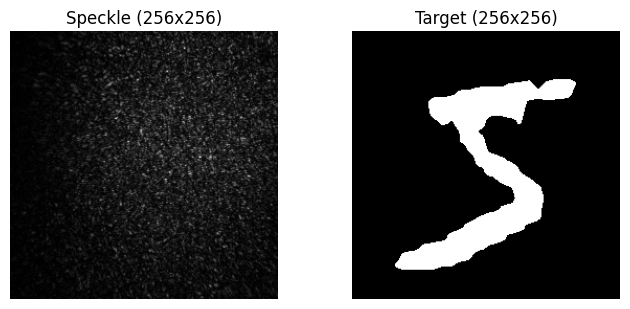

In [ ]:
#@title 5. TranSpeckle 2400 - verified filename families, object-wise split, D4 sealed
# Replace only Cell 6.  Uses ONLY TranSpeckle/data_sets/2400.
# Supports BOTH x1_0.tif and x1_big_0.tif (and analogous x2/x3/x4).
# No TIFF pixel data are read here. Cell 8 verifies actual GT matches across D1-D3.

from pathlib import Path
from collections import Counter, defaultdict
import hashlib
import json
import re
import numpy as np

DATA_ROOT_6 = Path('/content/drive/MyDrive/TranSpeckle/data_sets')
TRAIN_SET_6 = DATA_ROOT_6 / '2400'
if not TRAIN_SET_6.is_dir():
    raise FileNotFoundError(f'Missing official TranSpeckle dataset: {TRAIN_SET_6}')
if tuple(map(str, TRAIN_DIFFUSERS)) != ('1', '2', '3') or str(HELDOUT_DIFFUSER) != '4':
    raise RuntimeError('This experiment requires D1-D3 for training and D4 sealed for evaluation.')

# Examples: x1_0.tif -> (D1, standard, 0)
#           x1_big_0.tif -> (D1, big, 0)
# A variant is a filename FAMILY, NOT a verified Digit/Letter class.
pattern6 = re.compile(
    r'^x(?P<diffuser>[1-4])_(?:(?P<family>[A-Za-z][A-Za-z0-9_-]*)_)?(?P<object_number>\d+)$',
    re.IGNORECASE,
)

def parse_filename6(filename):
    m = pattern6.fullmatch(Path(filename).stem)
    if m is None:
        raise ValueError(f'Unsupported TranSpeckle filename: {filename}')
    return (m.group('diffuser'),
            (m.group('family') or 'standard').lower(),
            str(int(m.group('object_number'))))

# Quick deterministic parser checks.
assert parse_filename6('x1_0.tif') == ('1', 'standard', '0')
assert parse_filename6('x1_big_0.tif') == ('1', 'big', '0')
assert parse_filename6('x4_big_239.tif') == ('4', 'big', '239')

def read_metadata6(split):
    """Collect x/y paths only; do NOT inspect image content (especially D4/EVAL)."""
    xdir = TRAIN_SET_6 / f'x_{split}'
    ydir = TRAIN_SET_6 / f'y_{split}'
    if not xdir.is_dir() or not ydir.is_dir():
        raise FileNotFoundError(f'Missing paired folders: {xdir}, {ydir}')

    extensions = {'.tif', '.tiff'}
    xfiles = sorted((p for p in xdir.iterdir()
                     if p.is_file() and p.suffix.lower() in extensions),
                    key=lambda p: p.name)
    yfiles = {p.name: p for p in ydir.iterdir()
              if p.is_file() and p.suffix.lower() in extensions}
    if not xfiles or len(xfiles) != len(yfiles):
        raise RuntimeError(f'{split}: Speckle files={len(xfiles)}; GT files={len(yfiles)}.')

    by_object = defaultdict(dict)
    counts = Counter()
    unparsed = []
    for x_path in xfiles:
        y_path = yfiles.get(x_path.name)
        if y_path is None:
            raise RuntimeError(f'{split}: GT is missing for {x_path.name}')
        try:
            d, family, object_number = parse_filename6(x_path.name)
        except ValueError:
            unparsed.append(x_path.name)
            continue

        key = (family, object_number)
        if d in by_object[key]:
            raise RuntimeError(f'{split}: duplicate object/view: {key}, diffuser={d}')
        by_object[key][d] = dict(
            kind=family, object_id=object_number, diffuser=d,
            speckle_path=str(x_path), gt_path=str(y_path),
            source_split=split, filename=x_path.name,
        )
        counts[(family, d)] += 1

    if unparsed:
        raise RuntimeError(
            f'{split}: {len(unparsed)} filenames do not match the supported pattern. '
            f'First examples: {unparsed[:12]}. Do not guess identity.'
        )

    print(f'\nOFFICIAL {split.upper()}: {len(xfiles)} paired measurements, '
          f'{len(by_object)} filename-based four-view candidate objects')
    print('File counts by filename family and diffuser:')
    for family in sorted({family for family, _ in counts}):
        print(f'  {family}:', {d: counts[(family, d)] for d in ('1','2','3','4')})

    needed = {'1','2','3','4'}
    incomplete = [(k, sorted(needed-set(v))) for k, v in by_object.items()
                  if set(v) != needed]
    if incomplete:
        raise RuntimeError(
            f'{split}: {len(incomplete)} filename-based objects lack some diffusers. '
            f'First 10: {incomplete[:10]}. '
            'Check whether the source is actually a four-diffuser dataset.'
        )
    return dict(by_object)

# Read METADATA from original split. Official validation is sealed evaluation here.
official_train6 = read_metadata6('train')
official_eval6 = read_metadata6('valid')
if len(official_train6) < 100 or len(official_eval6) < 10:
    raise RuntimeError('Too few complete four-view objects for a full training experiment.')
if set(official_train6).intersection(official_eval6):
    raise RuntimeError('Same filename-family/object-number appears in official train and valid!')

# Be conservative: different filename families sharing the same numeric ID
# stay in the SAME internal split, to reduce possible object-identity leakage.
# This does not assert that different families with the same ID are identical objects.
object_ids6 = sorted({k[1] for k in official_train6}, key=lambda x: int(x))
rng6 = np.random.default_rng(SPLIT_SEED)
order6 = rng6.permutation(len(object_ids6))
ratio6 = TRAIN_OBJECT_FRACTION / (TRAIN_OBJECT_FRACTION + VALIDATION_OBJECT_FRACTION)
n_train_ids6 = int(len(object_ids6) * ratio6)
train_ids6 = {object_ids6[i] for i in order6[:n_train_ids6]}
val_ids6 = set(object_ids6) - train_ids6

sortkey6 = lambda k: (k[0], int(k[1]))
splits = {
    'TRAIN': sorted((k for k in official_train6 if k[1] in train_ids6), key=sortkey6),
    'VAL': sorted((k for k in official_train6 if k[1] in val_ids6), key=sortkey6),
    'EVAL': sorted(official_eval6, key=sortkey6),
}
complete = {**official_train6, **official_eval6}
records = [r for views in complete.values() for r in views.values()]

if not splits['TRAIN'] or not splits['VAL'] or not splits['EVAL']:
    raise RuntimeError('One of TRAIN/VAL/EVAL is empty after the object-wise split.')
assert len(set().union(*(set(v) for v in splits.values()))) == len(complete)
assert all(set(splits[a]).isdisjoint(splits[b]) for a,b in
           [('TRAIN','VAL'),('TRAIN','EVAL'),('VAL','EVAL')])
assert all(set(complete[k]) == {'1','2','3','4'}
           for g in splits.values() for k in g)

# Prevent silent reuse of a checkpoint from a differently parsed dataset/split.
manifest_for_hash6 = {
    'dataset': str(TRAIN_SET_6),
    'object_split': {name: keys for name,keys in splits.items()},
    'file_mapping': {f'{family}:{obj}': {d: complete[(family,obj)][d]['filename']
                       for d in sorted(complete[(family,obj)])}
                     for family,obj in sorted(complete, key=sortkey6)},
    'diffusers_train': list(TRAIN_DIFFUSERS),
    'heldout_diffuser': str(HELDOUT_DIFFUSER),
    'preprocessing': '2x2-bin-maxnorm-binary-GT-256',
}
SPLIT_FINGERPRINT = hashlib.sha256(
    json.dumps(manifest_for_hash6, sort_keys=True).encode()
).hexdigest()

print('\n=== DATA PLAN (before any training) ===')
for label, keys in splits.items():
    print(f'{label}: {len(keys)} object-family pairs | '
          f'{len(keys)*3} D1-D3 measurements | '
          f'{len(keys)} held-out D4 file paths (not opened)')
    print('  filename families:', dict(Counter(k[0] for k in keys)))
print('All four-view candidate groups:', len(complete))
print('Distinct numeric IDs in official TRAIN:', len(object_ids6))
print('Split fingerprint:', SPLIT_FINGERPRINT[:16])
print('D4 and official EVAL image data were NOT read.')
print('NEXT: Run Cell 8; it checks exact GT consistency across D1/D2/D3.')
print('NOTE: Filename family (e.g. big) is not assumed to mean Digit or Letter.')

# ---- Load TRAIN and VAL (D1-D3 only, threaded, cached) and verify the target is identical across diffusers ----
EXPECTED_SPLIT_FINGERPRINT = 'bd1dc0429c80e91b'     # the split of the contrastive-encoder notebook
assert SPLIT_FINGERPRINT[:16] == EXPECTED_SPLIT_FINGERPRINT, (
    'The object split differs from the contrastive-encoder notebook: ' + SPLIT_FINGERPRINT[:16])
FAMILY_LABEL = {'big': 'Digit', 'standard': 'Letter'}   # naming used in the shared reports (checked by eye on objects 270, 271)
# Processed arrays are identical for the same split fingerprint and preprocessing, so an existing cache is reused (read only).
CACHE_DIRS = [RESULTS_DIR, PROJECT / 'DiT_Pixel_X0_ContrastiveEncoder_D4HeldOut']

def load_views(split):
    keys = splits[split]
    pairs = [(complete[k][d]['speckle_path'], complete[k][d]['gt_path']) for k in keys for d in TRAIN_DIFFUSERS]
    name = f'cache_{split}_{SPLIT_FINGERPRINT[:12]}.npz'
    X = M = None
    for folder in CACHE_DIRS:
        if (folder / name).is_file():
            data = np.load(folder / name)
            if len(data['X']) == len(pairs):
                X, M = data['X'], data['M']
                print(f'{split}: loaded {len(X)} processed measurements from cache in {folder.name}')
                break
    if X is None:
        X = np.zeros((len(pairs), 256, 256), np.float32); M = np.zeros((len(pairs), 256, 256), np.uint8)
        tick = time.time()
        with ThreadPoolExecutor(max_workers=16) as pool:
            for i, (condition, mask) in enumerate(pool.map(load_pair, pairs)):
                X[i], M[i] = condition, mask
                if (i + 1) % 300 == 0 or i + 1 == len(pairs):
                    print(f'{split}: {i + 1}/{len(pairs)} measurements | {time.time() - tick:.0f}s', flush=True)
        local = Path('/content') / name
        np.savez(local, X=X, M=M); shutil.copy(local, RESULTS_DIR / name)
    Mv = M.reshape(len(keys), 3, 256, 256)
    if not ((Mv[:, 0] == Mv[:, 1]).all() and (Mv[:, 0] == Mv[:, 2]).all()):
        raise RuntimeError(f'{split}: an object has different targets across D1/D2/D3. Stop: the pairing is wrong.')
    names = [Path(complete[k][d]['filename']).stem for k in keys for d in TRAIN_DIFFUSERS]
    family = [FAMILY_LABEL.get(k[0], k[0]) for k in keys for d in TRAIN_DIFFUSERS]
    diffuser = ['D' + d for k in keys for d in TRAIN_DIFFUSERS]
    return torch.from_numpy(X), torch.from_numpy(M), names, family, diffuser

Xtr, Mtr, TRAIN_NAMES, _, _ = load_views('TRAIN')            # [N,256,256] float32 / uint8, order: object, then D1,D2,D3
Xva, Mva, VAL_NAMES, VAL_FAMILY, VAL_DIFFUSER = load_views('VAL')
assert len(splits['TRAIN']) == 444 and len(splits['VAL']) == 96 and len(splits['EVAL']) == 60, (
    len(splits['TRAIN']), len(splits['VAL']), len(splits['EVAL']))
assert Xtr.dtype == torch.float32 and Mtr.dtype == torch.uint8
assert tuple(Xtr.shape) == (1332, 256, 256) and tuple(Xva.shape) == (288, 256, 256)
assert torch.isfinite(Xtr).all() and torch.isfinite(Xva).all()
assert float(Xtr.min()) >= 0 and abs(float(Xtr.amax(dim=(1, 2)).min()) - 1.0) < 1e-6
assert set(torch.unique(Mtr).tolist()) <= {0, 1}
assert all(n.startswith(('x1_', 'x2_', 'x3_')) for n in TRAIN_NAMES + VAL_NAMES), 'A D4 file reached the training data'
print('TRAIN measurements:', len(Mtr), '| VAL measurements:', len(Mva))
print('Speckle range:', float(Xtr.min()), float(Xtr.max()), '| target values:', torch.unique(Mtr).tolist())
print('Mean foreground fraction: train %.4f | validation %.4f' % (float(Mtr.float().mean()), float(Mva.float().mean())))
print('No D4 image and no official x_valid/y_valid image was opened.')

def get_batch(X, M, ids):
    """Return (x_0 in {-1,+1}, Speckle in [0,1]) as float32 tensors of shape [B,1,256,256]."""
    ids = torch.as_tensor(ids, dtype=torch.long)
    return (2.0 * M[ids].float() - 1.0)[:, None], X[ids][:, None]

fig, ax = plt.subplots(1, 2, figsize=(7, 3.2))
ax[0].imshow(Xtr[0], cmap='gray', vmin=0, vmax=1); ax[0].set_title('Speckle (256x256)')
ax[1].imshow(Mtr[0], cmap='gray', vmin=0, vmax=1); ax[1].set_title('Target (256x256)')
for a in ax: a.axis('off')
plt.tight_layout(); plt.show(); plt.close(fig)

## Model: official DiT blocks, Speckle next to the time embedding and through the attention

In [ ]:
#@title 6. SpeckleDiT = official DiT + Speckle conditioner
class SpeckleConditioner(nn.Module):
    """Speckle image -> (tokens for the attention, global vector for adaLN-Zero)."""
    def __init__(self, hidden, patch, depth, heads):
        super().__init__()
        self.patch = nn.Conv2d(1, hidden, kernel_size=patch, stride=patch)
        n_tokens = (256 // patch) ** 2
        self.pos = nn.Parameter(torch.zeros(1, n_tokens, hidden))
        self.type_embed = nn.Parameter(torch.zeros(1, 1, hidden))
        layer = nn.TransformerEncoderLayer(d_model=hidden, nhead=heads, dim_feedforward=4 * hidden,
                                           dropout=0.0, activation='gelu', batch_first=True, norm_first=True)
        self.encoder = nn.TransformerEncoder(layer, depth, enable_nested_tensor=False) if depth > 0 else nn.Identity()
        self.norm = nn.LayerNorm(hidden)
        self.global_head = nn.Sequential(nn.Linear(hidden, hidden), nn.SiLU(), nn.Linear(hidden, hidden))
        nn.init.xavier_uniform_(self.patch.weight.view(hidden, -1)); nn.init.zeros_(self.patch.bias)
        nn.init.normal_(self.pos, std=0.02); nn.init.normal_(self.type_embed, std=0.02)
        nn.init.normal_(self.global_head[-1].weight, std=0.02); nn.init.zeros_(self.global_head[-1].bias)

    def forward(self, speckle):
        # Per-image standardisation inside the network (the stored data stay max-normalised in [0,1]).
        s = speckle.float()
        s = (s - s.mean(dim=(1, 2, 3), keepdim=True)) / s.std(dim=(1, 2, 3), keepdim=True).clamp_min(1e-6)
        tokens = self.patch(s).flatten(2).transpose(1, 2) + self.pos
        tokens = self.norm(self.encoder(tokens))
        return tokens + self.type_embed, self.global_head(tokens.mean(dim=1))

class SpeckleDiT(DiT):
    """Official DiT. Only the conditioning differs: the class-label table is replaced by a Speckle
    conditioner, and forward() appends the Speckle tokens to the image tokens before the blocks."""
    def __init__(self, speckle_patch, speckle_depth, use_tokens=True, use_global=True, **dit_kwargs):
        super().__init__(**dit_kwargs)
        hidden = self.pos_embed.shape[-1]
        self.y_embedder = nn.Identity()      # the ImageNet label table is not used
        self.speckle = SpeckleConditioner(hidden, speckle_patch, speckle_depth, self.num_heads)
        self.use_tokens, self.use_global = use_tokens, use_global

    def forward(self, x, t, y):
        x = self.x_embedder(x) + self.pos_embed
        n_image = x.shape[1]
        tokens, global_vec = self.speckle(y)
        c = self.t_embedder(t)
        if self.use_global:
            c = c + global_vec
        if self.use_tokens:
            x = torch.cat([x, tokens.to(x.dtype)], dim=1)
        for block in self.blocks:
            x = block(x, c)
        x = self.final_layer(x[:, :n_image], c)
        return self.unpatchify(x)

def build_model():
    return SpeckleDiT(speckle_patch=SPECKLE_PATCH, speckle_depth=SPECKLE_ENCODER_DEPTH,
                      use_tokens=USE_SPECKLE_TOKENS, use_global=USE_SPECKLE_GLOBAL,
                      input_size=256, patch_size=IMAGE_PATCH, in_channels=1,
                      hidden_size=DIT_HIDDEN, depth=DIT_DEPTH, num_heads=DIT_HEADS,
                      class_dropout_prob=0.0, num_classes=1, learn_sigma=False).to(DEVICE)

# Official diffusion: 1000 linear steps, x0-prediction, fixed variance, MSE loss.
diffusion_train = create_diffusion(timestep_respacing='', noise_schedule='linear',
                                   predict_xstart=True, learn_sigma=False, diffusion_steps=TRAIN_TIMESTEPS)
diffusion_ddim = create_diffusion(timestep_respacing=str(SAMPLE_STEPS), noise_schedule='linear',
                                  predict_xstart=True, learn_sigma=False, diffusion_steps=TRAIN_TIMESTEPS)
assert diffusion_train.num_timesteps == TRAIN_TIMESTEPS and diffusion_ddim.num_timesteps == SAMPLE_STEPS

_probe = build_model()
assert len(_probe.blocks) == DIT_DEPTH and _probe.in_channels == 1 and _probe.out_channels == 1
_x = torch.randn(2, 1, 256, 256, device=DEVICE); _s = torch.rand(2, 1, 256, 256, device=DEVICE)
_t = torch.tensor([10, 900], device=DEVICE)
with torch.autocast('cuda', dtype=torch.float16):
    _out = _probe(_x, _t, _s)
    _loss = diffusion_train.training_losses(_probe, _x.sign(), _t, model_kwargs={'y': _s})['loss'].float().mean()
assert _out.shape == (2, 1, 256, 256) and torch.isfinite(_out).all()
assert float(_out.detach().abs().max()) == 0, 'Official DiT must output zeros at initialisation'
_loss.backward()
assert _probe.final_layer.linear.weight.grad.abs().sum() > 0, 'Loss does not reach the output layer'
print('PASS: official DiT blocks, %d image tokens + %d Speckle tokens, x0-prediction loss = %.4f' % (
    (256 // IMAGE_PATCH) ** 2, (256 // SPECKLE_PATCH) ** 2 if USE_SPECKLE_TOKENS else 0, float(_loss)))
print('Parameters: %.2fM' % (sum(p.numel() for p in _probe.parameters() if p.requires_grad) / 1e6))
del _probe, _x, _s, _t, _out, _loss
torch.cuda.empty_cache()

PASS: official DiT blocks, 256 image tokens + 256 Speckle tokens, x0-prediction loss = 1.0000
Parameters: 36.70M


/tmp/ipykernel_370/4156346346.py:77: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  (256 // IMAGE_PATCH) ** 2, (256 // SPECKLE_PATCH) ** 2 if USE_SPECKLE_TOKENS else 0, float(_loss)))


In [ ]:
#@title 7. DDIM sampling from pure noise, metrics, Speckle-swap test
@torch.inference_mode()
def sample_x0(net, speckle, seed, batch=16):
    """speckle: [N,1,256,256] in [0,1]. Returns reconstructions in [-1,1], starting from pure noise."""
    net.eval()
    generator = torch.Generator(device='cpu').manual_seed(seed)
    noise = torch.randn(len(speckle), 1, 256, 256, generator=generator)
    outputs = []
    for st in range(0, len(speckle), batch):
        s = speckle[st:st + batch].to(DEVICE); z = noise[st:st + batch].to(DEVICE)
        with torch.autocast('cuda', dtype=torch.float16):
            x = diffusion_ddim.ddim_sample_loop(net, tuple(z.shape), noise=z, clip_denoised=True,
                                                model_kwargs={'y': s}, device=DEVICE, progress=False, eta=0.0)
        outputs.append(x.float().clamp(-1, 1).cpu())
    return torch.cat(outputs)

def im_metrics(output, truth):
    a = np.clip((np.asarray(output, np.float32).reshape(256, 256) + 1) / 2, 0, 1)
    b = np.clip((np.asarray(truth, np.float32).reshape(256, 256) + 1) / 2, 0, 1)
    mse = float(np.mean((a - b) ** 2))
    aa, bb = a > .5, b > .5
    inter = np.logical_and(aa, bb).sum(); union = np.logical_or(aa, bb).sum()
    pcc = float('nan') if (np.std(a) < 1e-9 or np.std(b) < 1e-9) else float(np.corrcoef(a.ravel(), b.ravel())[0, 1])
    return dict(MSE=mse, PSNR=float(-10 * np.log10(max(1e-12, mse))),
                SSIM=float(structural_similarity(b, a, data_range=1)),
                Dice=float((2 * inter + 1) / (aa.sum() + bb.sum() + 1)), IoU=float((inter + 1) / (union + 1)), PCC=pcc)

def evaluate(net, X, M, ids, seed):
    x0, speckle = get_batch(X, M, ids)
    pred = sample_x0(net, speckle, seed)
    frame = pd.DataFrame([im_metrics(pred[i].numpy(), x0[i].numpy()) for i in range(len(ids))])
    frame.insert(0, 'Index', [int(i) for i in ids])
    return frame, pred, x0

def swap_partner(M, ids):
    """For every index pick another index of the list whose target mask is different."""
    ids = [int(i) for i in ids]; partners = []
    for k, i in enumerate(ids):
        for shift in range(len(ids) // 2, len(ids) // 2 + len(ids)):
            j = ids[(k + shift) % len(ids)]
            if j != i and not torch.equal(M[i], M[j]):
                partners.append(j); break
        else:
            raise RuntimeError('No sample with a different target found for the swap test')
    return partners

def swap_test(net, X, M, ids, seed):
    """Same noise, correct Speckle vs the Speckle of a DIFFERENT object. Both compared with the true target."""
    ids = [int(i) for i in ids]; partners = swap_partner(M, ids)
    x0, speckle = get_batch(X, M, ids)
    _, speckle_wrong = get_batch(X, M, partners)
    good = sample_x0(net, speckle, seed); wrong = sample_x0(net, speckle_wrong, seed)
    g = pd.DataFrame([im_metrics(good[i].numpy(), x0[i].numpy()) for i in range(len(ids))])
    w = pd.DataFrame([im_metrics(wrong[i].numpy(), x0[i].numpy()) for i in range(len(ids))])
    return dict(Dice_correct=float(g.Dice.mean()), Dice_swapped=float(w.Dice.mean()),
                MSE_correct=float(g.MSE.mean()), MSE_swapped=float(w.MSE.mean()),
                Correct_better_pct=float(100 * (g.Dice.values > w.Dice.values).mean()),
                Output_change=float((good - wrong).abs().mean())), good, x0

def show_examples(rows, titles, path=None):
    n = rows[0].shape[0]
    fig, axs = plt.subplots(len(rows), n, figsize=(2.2 * n, 2.3 * len(rows)), squeeze=False)
    for r, (images, title) in enumerate(zip(rows, titles)):
        for j in range(n):
            img = images[j, 0].numpy()
            axs[r, j].imshow(img if title == 'Speckle' else (img + 1) / 2, cmap='gray', vmin=0, vmax=1)
            axs[r, j].set_title(title, fontsize=8); axs[r, j].axis('off')
    plt.tight_layout()
    if path is not None:
        fig.savefig(path, dpi=130, bbox_inches='tight')
    plt.show(); plt.close(fig)
print('Sampler: DDIM', SAMPLE_STEPS, 'steps from pure Gaussian noise, eta=0, clip to [-1,1]')

Sampler: DDIM 50 steps from pure Gaussian noise, eta=0, clip to [-1,1]


## Sanity test: can the model overfit 4 pairs **and** does it use the Speckle?

SANITY 1/2500 | x0 MSE loss=1.00000 | steps/s=4.14
SANITY 500/2500 | x0 MSE loss=0.15198 | steps/s=14.24
SANITY 1000/2500 | x0 MSE loss=0.05295 | steps/s=14.29
SANITY 1500/2500 | x0 MSE loss=0.01457 | steps/s=14.27
SANITY 2000/2500 | x0 MSE loss=0.00663 | steps/s=14.38
SANITY 2500/2500 | x0 MSE loss=0.00696 | steps/s=14.39
SANITY RESULT (4 training pairs, full DDIM from noise):
Dice_correct            0.97046
Dice_swapped            0.38458
MSE_correct             0.00698
MSE_swapped             0.16758
Correct_better_pct    100.00000
Output_change           0.34538


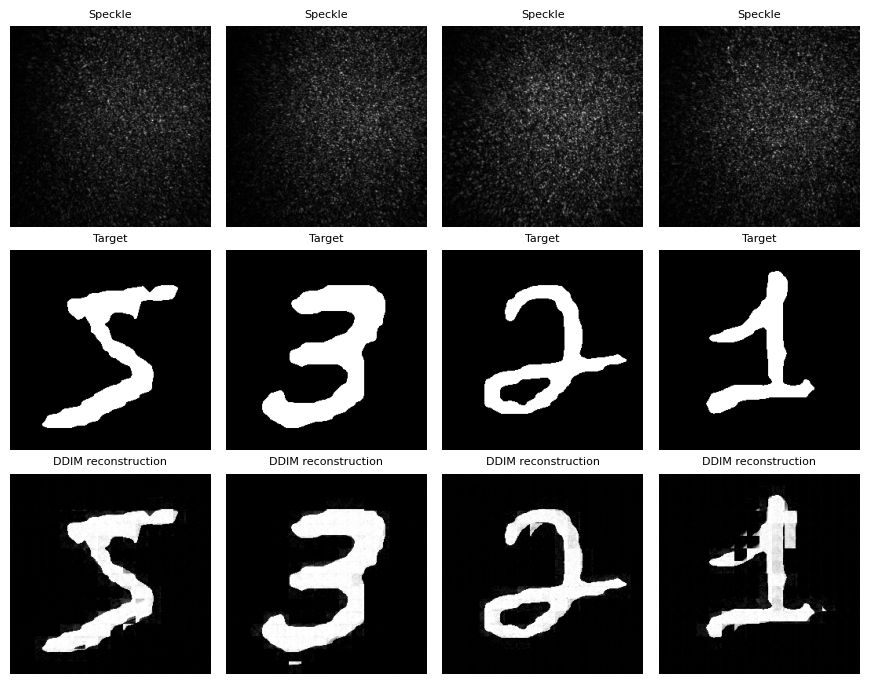

SANITY PASS | required: Dice_correct >= 0.80 and Dice_correct - Dice_swapped >= 0.30


In [ ]:
#@title 8. 4-pair overfit + Speckle-swap test (stops the notebook if the Speckle is ignored)
if not RUN_SANITY:
    print('RUN_SANITY=False: skipped')
else:
    step_ids = np.linspace(0, len(Xtr) - 1, 64, dtype=int).tolist()
    sanity_ids = []
    for i in step_ids:
        if all(not torch.equal(Mtr[i], Mtr[j]) for j in sanity_ids):
            sanity_ids.append(i)
        if len(sanity_ids) == 4: break
    assert len(sanity_ids) == 4, 'Could not find 4 training pairs with different targets'
    torch.manual_seed(SEED + 1)
    sanity_model = build_model()
    sanity_opt = torch.optim.AdamW(sanity_model.parameters(), lr=SANITY_LR, weight_decay=0.0)
    sanity_scaler = torch.amp.GradScaler('cuda')
    sx0, sspeckle = get_batch(Xtr, Mtr, sanity_ids)
    sx0, sspeckle = sx0.to(DEVICE), sspeckle.to(DEVICE)
    tick = time.time(); window = []
    for step in range(1, SANITY_STEPS + 1):
        sanity_model.train()
        t = torch.randint(0, TRAIN_TIMESTEPS, (4,), device=DEVICE)
        sanity_opt.zero_grad(set_to_none=True)
        with torch.autocast('cuda', dtype=torch.float16):
            loss = diffusion_train.training_losses(sanity_model, sx0, t, model_kwargs={'y': sspeckle})['loss'].float().mean()
        if not torch.isfinite(loss): raise RuntimeError(f'Non-finite sanity loss at step {step}')
        sanity_scaler.scale(loss).backward(); sanity_scaler.step(sanity_opt); sanity_scaler.update()
        window.append(loss.item())
        if step == 1 or step % 500 == 0:
            print(f'SANITY {step}/{SANITY_STEPS} | x0 MSE loss={np.mean(window):.5f} | steps/s={step / (time.time() - tick):.2f}', flush=True)
            window.clear()
    sanity_result, sanity_pred, sanity_truth = swap_test(sanity_model, Xtr, Mtr, sanity_ids, seed=SEED + 2)
    print('SANITY RESULT (4 training pairs, full DDIM from noise):')
    print(pd.Series(sanity_result).round(5).to_string())
    show_examples([sspeckle.cpu(), sanity_truth, sanity_pred], ['Speckle', 'Target', 'DDIM reconstruction'],
                  RESULTS_DIR / 'sanity_4_pairs.png')
    sanity_ok = sanity_result['Dice_correct'] >= 0.80 and (sanity_result['Dice_correct'] - sanity_result['Dice_swapped']) >= 0.30
    print('SANITY', 'PASS' if sanity_ok else 'FAIL',
          '| required: Dice_correct >= 0.80 and Dice_correct - Dice_swapped >= 0.30')
    del sanity_model, sanity_opt, sanity_scaler; torch.cuda.empty_cache()
    if SANITY_GATE and not sanity_ok:
        raise RuntimeError('Sanity test failed: the model does not reconstruct 4 training pairs from their Speckle. '
                           'Do not start the long run. Try a larger SANITY_STEPS first; if it still fails, the '
                           'conditioning must be changed.')

## Long training — resumable

Three kinds of checkpoint are written. Every save goes to the local disk first, is copied to Drive under
a **new file name**, and the Drive copy is compared with the local file (size and SHA-256) before the
older file of that kind is removed. The step and epoch used in every report are read from inside the file.

- `latest_stepNNNNNN.pt` — everything needed to resume, every 5,000 updates.
- `best_dice_ema_stepNNNNNN.pt` — EMA with the best Dice of the full DDIM reconstruction (every 10,000 updates).
- `best_loss_ema_epochNNNN.pt` — EMA with the lowest validation loss (checked every 2 epochs).

In [ ]:
#@title 9. Training setup: model, EMA, optimizer, verified checkpoints, resume
torch.manual_seed(SEED)
model = build_model()
ema = copy.deepcopy(model).eval()
for p in ema.parameters(): p.requires_grad_(False)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.0)
scaler = torch.amp.GradScaler('cuda')

RECIPE = dict(git=repo_sha, split=SPLIT_FINGERPRINT, train_diffusers=list(TRAIN_DIFFUSERS), hidden=DIT_HIDDEN,
              depth=DIT_DEPTH, heads=DIT_HEADS, image_patch=IMAGE_PATCH, speckle_patch=SPECKLE_PATCH,
              speckle_depth=SPECKLE_ENCODER_DEPTH, tokens=USE_SPECKLE_TOKENS, global_vec=USE_SPECKLE_GLOBAL,
              prediction='x0', variance='fixed', schedule='linear', timesteps=TRAIN_TIMESTEPS, lr=LR, ema=EMA_DECAY,
              batch=BATCH_SIZE, seed=SEED)
RECIPE_HASH = hashlib.sha256(json.dumps(RECIPE, sort_keys=True).encode()).hexdigest()
HISTORY_CSV = RESULTS_DIR / 'history.csv'                 # one row per full DDIM evaluation
EPOCH_CSV = RESULTS_DIR / 'epoch_history.csv'             # one row per epoch
LOCAL_DIR = Path('/content/checkpoints_local'); LOCAL_DIR.mkdir(exist_ok=True)
LOCAL_BEST_LOSS = LOCAL_DIR / 'best_loss_ema_pending.pt'
STEPS_PER_EPOCH = math.ceil(len(Xtr) / BATCH_SIZE)
history = []; epoch_log = []; start_step = 1
best_dice = -1.0; best_step = 0
best_loss = float('inf'); best_loss_epoch = 0; best_loss_step = 0; best_loss_dirty = False
epoch_sum = 0.0; epoch_n = 0

@torch.no_grad()
def update_ema(step):
    # Meta's update rule; the decay ramps up at the start so early evaluations are not dominated by the initial weights.
    decay = min(EMA_DECAY, (1 + step) / (10 + step))
    m = OrderedDict(model.named_parameters()); e = OrderedDict(ema.named_parameters())
    for key in m: e[key].mul_(decay).add_(m[key].data, alpha=1 - decay)

def file_sha256(path):
    digest = hashlib.sha256()
    with open(path, 'rb') as handle:
        for chunk in iter(lambda: handle.read(1 << 24), b''):
            digest.update(chunk)
    return digest.hexdigest()

def publish_file(local, name, family, remove_local=True):
    """Copy a finished local file to Drive under `name`, verify the copy, then keep only the two newest files of
    this family. A checkpoint on Drive is never replaced by renaming another file over it."""
    destination = RESULTS_DIR / name
    local_hash = file_sha256(local)
    for attempt in range(3):
        shutil.copyfile(local, destination)
        time.sleep(2 * attempt)
        if destination.stat().st_size == local.stat().st_size and file_sha256(destination) == local_hash:
            break
        print(f'Drive copy of {name} did not verify (attempt {attempt + 1}); copying again', flush=True)
    else:
        raise RuntimeError(f'The Drive copy of {name} differs from the local file after 3 attempts. Check the Drive storage quota.')
    if remove_local:
        local.unlink()
    for old in sorted(RESULTS_DIR.glob(family + '*.pt'))[:-2]:
        old.unlink()
    return destination

def save_latest(step):
    global best_loss_dirty
    if best_loss_dirty:      # the best-validation-loss EMA waits on the local disk between checkpoints
        publish_file(LOCAL_BEST_LOSS, 'best_loss_ema_epoch%04d.pt' % best_loss_epoch, 'best_loss_ema_epoch', remove_local=False)
        best_loss_dirty = False
    state = dict(step=step, model=model.state_dict(), ema=ema.state_dict(), optimizer=optimizer.state_dict(),
                 scaler=scaler.state_dict(), history=history, epoch_log=epoch_log,
                 best_dice=best_dice, best_step=best_step,
                 best_loss=best_loss, best_loss_epoch=best_loss_epoch, best_loss_step=best_loss_step,
                 epoch_sum=epoch_sum, epoch_n=epoch_n, recipe=RECIPE, recipe_hash=RECIPE_HASH)
    local = LOCAL_DIR / ('latest_step%06d.pt' % step)
    torch.save(state, local)
    publish_file(local, local.name, 'latest_step')
    pd.DataFrame(history).to_csv(HISTORY_CSV, index=False)
    pd.DataFrame(epoch_log).to_csv(EPOCH_CSV, index=False)

CHECKPOINT_PATTERN = {'best_loss': 'best_loss_ema_epoch*.pt', 'best_dice': 'best_dice_ema_step*.pt', 'last': 'latest_step*.pt'}
CHECKPOINT_LABEL = {'best_loss': 'Best loss', 'best_dice': 'Best Dice', 'last': 'Last'}

def load_checkpoint(kind):
    """Newest Drive file of this kind -> dict(ema, step, epoch, file). Step and epoch are read from inside the file."""
    files = sorted(RESULTS_DIR.glob(CHECKPOINT_PATTERN[kind]))
    assert files, f'No {kind} checkpoint in {RESULTS_DIR}: run the training cell first.'
    ckpt = torch.load(files[-1], map_location='cpu', weights_only=False)
    assert ckpt['recipe_hash'] == RECIPE_HASH, 'This checkpoint was made with a different configuration'
    step = int(ckpt['step']); epoch = int(ckpt.get('epoch', math.ceil(step / STEPS_PER_EPOCH)))
    expected = {'best_loss': best_loss_step, 'best_dice': best_step, 'last': 0}[kind]
    if expected and expected != step:
        print(f'WARNING: training recorded the {kind} checkpoint at step {expected}, but the newest file on Drive '
              f'({files[-1].name}) holds step {step}. Results below are labelled with the step in the file.')
    return dict(ema=ckpt['ema'], step=step, epoch=epoch, file=files[-1].name)

resumed = False
for candidate in sorted(RESULTS_DIR.glob('latest_step*.pt'), reverse=True):
    try:
        ckpt = torch.load(candidate, map_location='cpu', weights_only=False)
    except Exception as error:
        print('Skipping an unreadable checkpoint:', candidate.name, repr(error)[:120]); continue
    assert ckpt.get('recipe_hash') == RECIPE_HASH, ('The checkpoint in the results directory was made with a different '
                                                    'configuration or dataset. Change RESULTS_NAME in Cell 1.')
    model.load_state_dict(ckpt['model']); ema.load_state_dict(ckpt['ema'])
    optimizer.load_state_dict(ckpt['optimizer']); scaler.load_state_dict(ckpt['scaler'])
    history = ckpt['history']; epoch_log = ckpt['epoch_log']
    best_dice = ckpt['best_dice']; best_step = ckpt['best_step']
    best_loss = ckpt['best_loss']; best_loss_epoch = ckpt['best_loss_epoch']; best_loss_step = ckpt['best_loss_step']
    epoch_sum = ckpt['epoch_sum']; epoch_n = ckpt['epoch_n']
    start_step = int(ckpt['step']) + 1; resumed = True
    print('RESUMING from', candidate.name, '| next step', start_step,
          '| best Dice %.4f at step %d | best validation loss %.5f at epoch %d' % (best_dice, best_step, best_loss, best_loss_epoch))
    del ckpt
    break
if not resumed:
    print('NEW training run | results directory:', RESULTS_DIR)
try:
    free_gb = shutil.disk_usage(MYDRIVE).free / 2 ** 30
    print('Free space reported by Drive: %.1f GB' % free_gb, '' if free_gb > 4 else '| WARNING: less than 4 GB free')
except Exception as error:
    print('Drive free space is not available:', repr(error)[:80])

eval_ids = np.linspace(0, len(Xva) - 1, min(EVAL_SUBSET, len(Xva)), dtype=int).tolist()
_g = torch.Generator(device='cpu').manual_seed(SEED + 5)
val_t = torch.randint(0, TRAIN_TIMESTEPS, (len(Xva),), generator=_g)
val_noise = torch.randn(len(Xva), 1, 256, 256, generator=_g)

@torch.inference_mode()
def val_single_step_mse(net):
    """x0-prediction MSE on all validation measurements with fixed timesteps and noise (not a full reconstruction)."""
    net.eval(); total = 0.0
    for st in range(0, len(Xva), 32):
        ids = list(range(st, min(st + 32, len(Xva))))
        x0, speckle = get_batch(Xva, Mva, ids)
        x0, speckle = x0.to(DEVICE), speckle.to(DEVICE)
        t = val_t[ids].to(DEVICE); noise = val_noise[ids].to(DEVICE)
        with torch.autocast('cuda', dtype=torch.float16):
            xt = diffusion_train.q_sample(x0, t, noise=noise)
            pred = net(xt, t, speckle).float()
        total += float(F.mse_loss(pred, x0, reduction='sum'))
    return total / (len(Xva) * 256 * 256)
print('Updates per epoch:', STEPS_PER_EPOCH, '| total epochs: %.1f' % (TRAIN_STEPS / STEPS_PER_EPOCH))

RESUMING from latest_step100000.pt | next step 100001 | best Dice 0.5240 at step 30000 | best validation loss 0.09264 at epoch 80
Free space reported by Drive: 68.9 GB 
Updates per epoch: 167 | total epochs: 598.8


In [ ]:
#@title 10. Train with the official diffusion.training_losses (x0-prediction)
if not RUN_TRAINING:
    print('RUN_TRAINING=False: skipped')
else:
    tick = time.time(); window = []; current_epoch = -1; perm = None; train_loss_recent = float('nan')
    for step in range(start_step, TRAIN_STEPS + 1):
        epoch = (step - 1) // STEPS_PER_EPOCH
        if epoch != current_epoch:      # same shuffling as a seeded DataLoader, and identical after a resume
            perm = torch.randperm(len(Xtr), generator=torch.Generator(device='cpu').manual_seed(SEED + epoch))
            current_epoch = epoch
        pos = ((step - 1) % STEPS_PER_EPOCH) * BATCH_SIZE
        x0, speckle = get_batch(Xtr, Mtr, perm[pos:pos + BATCH_SIZE])
        x0, speckle = x0.to(DEVICE), speckle.to(DEVICE)
        t = torch.randint(0, TRAIN_TIMESTEPS, (len(x0),), device=DEVICE)
        model.train(); optimizer.zero_grad(set_to_none=True)
        with torch.autocast('cuda', dtype=torch.float16):
            loss = diffusion_train.training_losses(model, x0, t, model_kwargs={'y': speckle})['loss'].float().mean()
        if not torch.isfinite(loss):
            raise RuntimeError(f'Non-finite loss at step {step}')
        scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update()
        update_ema(step)
        value = loss.item(); window.append(value); epoch_sum += value; epoch_n += 1
        if step == start_step or step % PROGRESS_EVERY == 0:
            print(f'{step:,}/{TRAIN_STEPS:,} | epoch {epoch + 1} | train x0 MSE={np.mean(window):.5f} '
                  f'| steps/s={(step - start_step + 1) / max(time.time() - tick, 1e-6):.2f}', flush=True)
            train_loss_recent = float(np.mean(window)); window.clear()
        if step % STEPS_PER_EPOCH == 0 or step == TRAIN_STEPS:      # end of an epoch
            entry = dict(Epoch=epoch + 1, Step=step, TRAIN_x0_MSE=epoch_sum / max(epoch_n, 1), VAL_x0_MSE=float('nan'))
            epoch_sum = 0.0; epoch_n = 0
            if (epoch + 1) % VAL_LOSS_EVERY_EPOCHS == 0 or step == TRAIN_STEPS:
                entry['VAL_x0_MSE'] = val_single_step_mse(ema)
                if entry['VAL_x0_MSE'] < best_loss:
                    best_loss = entry['VAL_x0_MSE']; best_loss_epoch = epoch + 1; best_loss_step = step
                    torch.save(dict(ema=ema.state_dict(), step=step, epoch=epoch + 1, val_loss=best_loss,
                                    recipe_hash=RECIPE_HASH, recipe=RECIPE), LOCAL_BEST_LOSS)
                    best_loss_dirty = True
            epoch_log.append(entry)
        if step % EVAL_EVERY == 0 or step == TRAIN_STEPS:
            frame, _, _ = evaluate(ema, Xva, Mva, eval_ids, seed=SEED + 9)
            row = dict(Step=step, Epoch=epoch + 1, TRAIN_x0_MSE=train_loss_recent,
                       VAL_single_step_MSE=val_single_step_mse(ema),
                       VAL_DDIM_PSNR=float(frame.PSNR.mean()), VAL_DDIM_SSIM=float(frame.SSIM.mean()),
                       VAL_DDIM_Dice=float(frame.Dice.mean()), VAL_DDIM_PCC=float(frame.PCC.mean()))
            history.append(row)
            print('VALIDATION (EMA, DDIM from noise, %d known-diffuser measurements of unseen objects):' % len(eval_ids),
                  {k: (round(v, 5) if isinstance(v, float) else v) for k, v in row.items()}, flush=True)
            print('Best validation loss so far: %.5f at epoch %d' % (best_loss, best_loss_epoch), flush=True)
            if row['VAL_DDIM_Dice'] > best_dice:      # full reconstruction, not the single-step loss
                best_dice = row['VAL_DDIM_Dice']; best_step = step
                local = LOCAL_DIR / ('best_dice_ema_step%06d.pt' % step)
                torch.save(dict(ema=ema.state_dict(), step=step, epoch=epoch + 1, dice=best_dice,
                                recipe_hash=RECIPE_HASH, recipe=RECIPE), local)
                publish_file(local, local.name, 'best_dice_ema_step')
                print('NEW BEST-DICE EMA saved and verified on Drive at step', step, flush=True)
        if step % CHECKPOINT_EVERY == 0 or step == TRAIN_STEPS:
            save_latest(step)
    print('TRAINING COMPLETE:', TRAIN_STEPS, 'updates | best validation Dice %.4f at step %d | best validation loss %.5f at epoch %d' % (
        best_dice, best_step, best_loss, best_loss_epoch))
    print('Checkpoint files on Drive:')
    for path in sorted(RESULTS_DIR.glob('*.pt')):
        print('  %-36s %12d bytes' % (path.name, path.stat().st_size))

TRAINING COMPLETE: 100000 updates | best validation Dice 0.5240 at step 30000 | best validation loss 0.09264 at epoch 80
Checkpoint files on Drive:
  best_dice_ema_step020000.pt             147269648 bytes
  best_dice_ema_step030000.pt             147269648 bytes
  best_loss_ema_epoch0058.pt              147269071 bytes
  best_loss_ema_epoch0080.pt              147269071 bytes
  latest_step095000.pt                    588324139 bytes
  latest_step100000.pt                    588325931 bytes


## Validation: unseen objects through the known diffusers D1–D3 (288 measurements, DDIM 50 steps)

Best loss checkpoint | step 13,360 (epoch 80) | 288 validation measurements, D1-D3, unseen objects | DDIM-50
PSNR   : 9.902774 +- 2.550502
SSIM   : 0.762290 +- 0.076945
Dice   : 0.474734 +- 0.137044
PCC    : 0.419715 +- 0.159800
MSE    : 0.116074 +- 0.048212
MSE_x0 : 0.464297 +- 0.192847

Best Dice checkpoint | step 30,000 (epoch 180) | 288 validation measurements, D1-D3, unseen objects | DDIM-50
PSNR   : 10.278486 +- 2.802513
SSIM   : 0.766710 +- 0.074306
Dice   : 0.511053 +- 0.148347
PCC    : 0.458866 +- 0.173182
MSE    : 0.109020 +- 0.049422
MSE_x0 : 0.436080 +- 0.197690

Last checkpoint | step 100,000 (epoch 599) | 288 validation measurements, D1-D3, unseen objects | DDIM-50
PSNR   : 10.422174 +- 2.820386
SSIM   : 0.775386 +- 0.072908
Dice   : 0.500790 +- 0.161014
PCC    : 0.454184 +- 0.184406
MSE    : 0.105589 +- 0.048209
MSE_x0 : 0.422354 +- 0.192834

Blank (all-black) image: PSNR 9.7961 | SSIM 0.8389 | Dice 0.0002
Best-Dice checkpoint by family:
          Dice                   

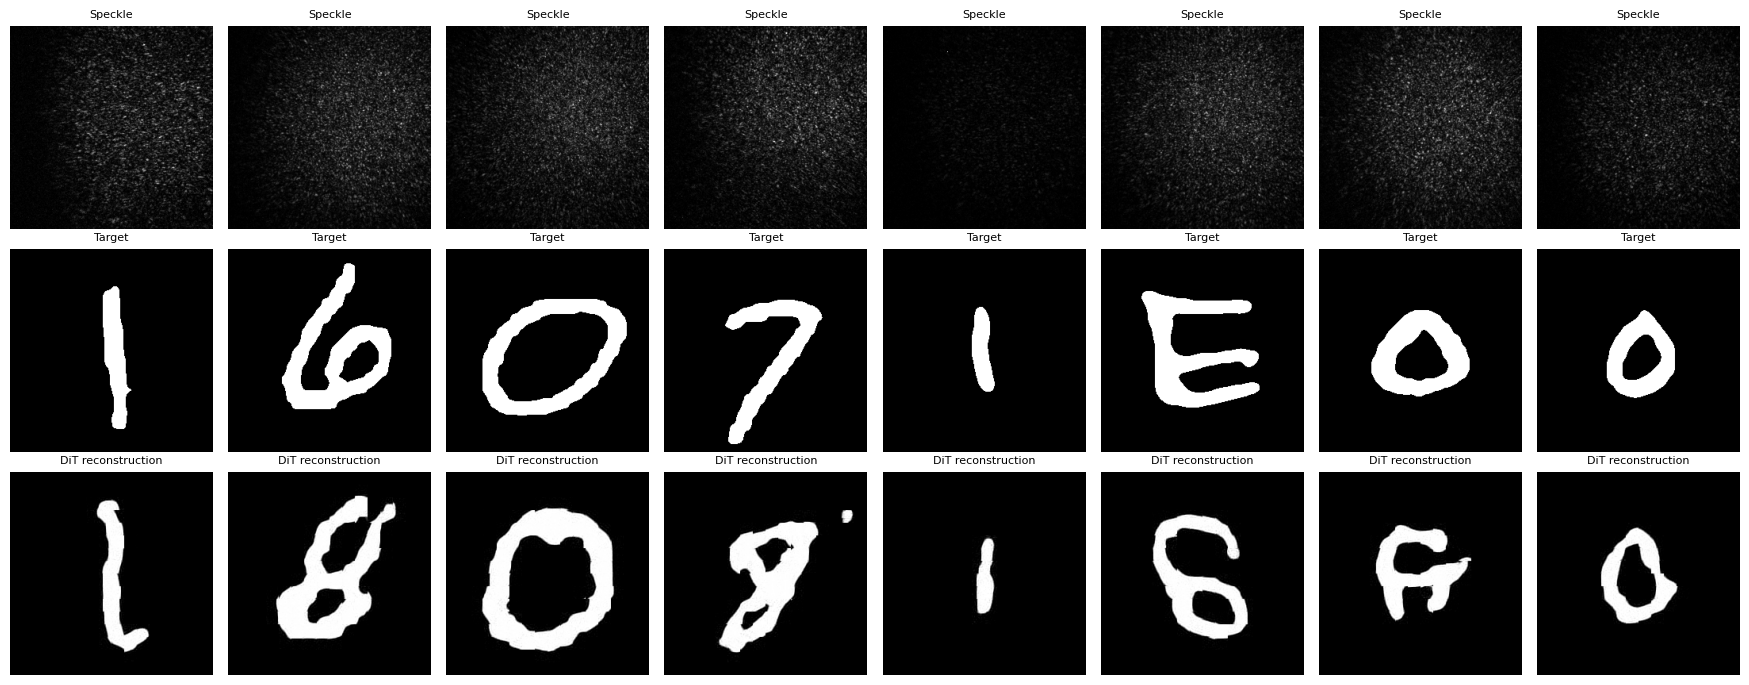

Saved to /content/drive/MyDrive/Speckle_Project/DiT_Pixel_X0_SpeckleTokens_D4HeldOut


In [ ]:
#@title 11. Validation metrics for the three checkpoints, Speckle-swap test, examples
METRICS = ['PSNR', 'SSIM', 'Dice', 'PCC', 'MSE', 'MSE_x0']     # MSE on [0,1]; MSE_x0 = 4*MSE is the MSE on the x_0 scale [-1,1]
CHECKPOINT_KINDS = ('best_loss', 'best_dice', 'last')

def summary_rows(frame, kind, ckpt, extra=None):
    rows = []
    for metric in METRICS:
        values = frame[metric]
        rows.append(dict(**(extra or {}), checkpoint=kind, epoch=ckpt['epoch'], pairs=len(frame), metric=metric,
                         mean=float(values.mean()), std=float(values.std()),
                         undefined_count=int(values.isna().sum()), infinite_count=int(np.isinf(values).sum())))
    return rows

def print_block(title, frame):
    print(title)
    for metric in METRICS:
        print('%-7s: %.6f +- %.6f' % (metric, frame[metric].mean(), frame[metric].std()))
    print(flush=True)

eval_net = copy.deepcopy(ema).eval()
all_ids = list(range(len(Mva)))
val_rows = []; val_results = {}
for kind in CHECKPOINT_KINDS:
    ckpt = load_checkpoint(kind); eval_net.load_state_dict(ckpt['ema'], strict=True)
    frame, pred, truth = evaluate(eval_net, Xva, Mva, all_ids, seed=SEED + 11)     # same starting noise for every checkpoint
    frame['MSE_x0'] = 4 * frame['MSE']
    frame.insert(1, 'Name', VAL_NAMES); frame.insert(2, 'Family', VAL_FAMILY); frame.insert(3, 'Diffuser', VAL_DIFFUSER)
    frame.to_csv(RESULTS_DIR / f'validation_metrics_{kind}.csv', index=False)
    val_rows += summary_rows(frame, kind, ckpt); val_results[kind] = (ckpt, frame, pred)
    print_block('%s checkpoint | step %s (epoch %d) | %d validation measurements, D1-D3, unseen objects | DDIM-%d' % (
        CHECKPOINT_LABEL[kind], format(ckpt['step'], ','), ckpt['epoch'], len(frame), SAMPLE_STEPS), frame)
pd.DataFrame(val_rows).to_csv(RESULTS_DIR / 'summary_metrics.csv', index=False)

blank = pd.DataFrame([im_metrics(-np.ones((256, 256), np.float32), truth[i].numpy()) for i in all_ids])
print('Blank (all-black) image: PSNR %.4f | SSIM %.4f | Dice %.4f' % (blank.PSNR.mean(), blank.SSIM.mean(), blank.Dice.mean()))
ckpt, frame, pred = val_results['best_dice']
print('Best-Dice checkpoint by family:'); print(frame.groupby('Family')[['Dice', 'PSNR', 'SSIM', 'PCC']].agg(['mean', 'std', 'count']).round(4).to_string())
print('Best-Dice checkpoint by diffuser:'); print(frame.groupby('Diffuser')[['Dice', 'PSNR', 'SSIM', 'PCC']].mean().round(4).to_string())
eval_net.load_state_dict(ckpt['ema'], strict=True)
swap_result, _, _ = swap_test(eval_net, Xva, Mva, eval_ids, seed=SEED + 12)
print('SPECKLE-SWAP TEST on %d validation measurements (does the reconstruction depend on the measurement?):' % len(eval_ids))
print(pd.Series(swap_result).round(5).to_string())
pd.Series(swap_result).to_csv(RESULTS_DIR / 'validation_swap_test.csv')
show_ids = np.linspace(0, len(Mva) - 1, 8, dtype=int).tolist()
show_examples([Xva[show_ids][:, None], truth[show_ids], pred[show_ids]],
              ['Speckle', 'Target', 'DiT reconstruction'], RESULTS_DIR / 'validation_examples.png')
print('Saved to', RESULTS_DIR)

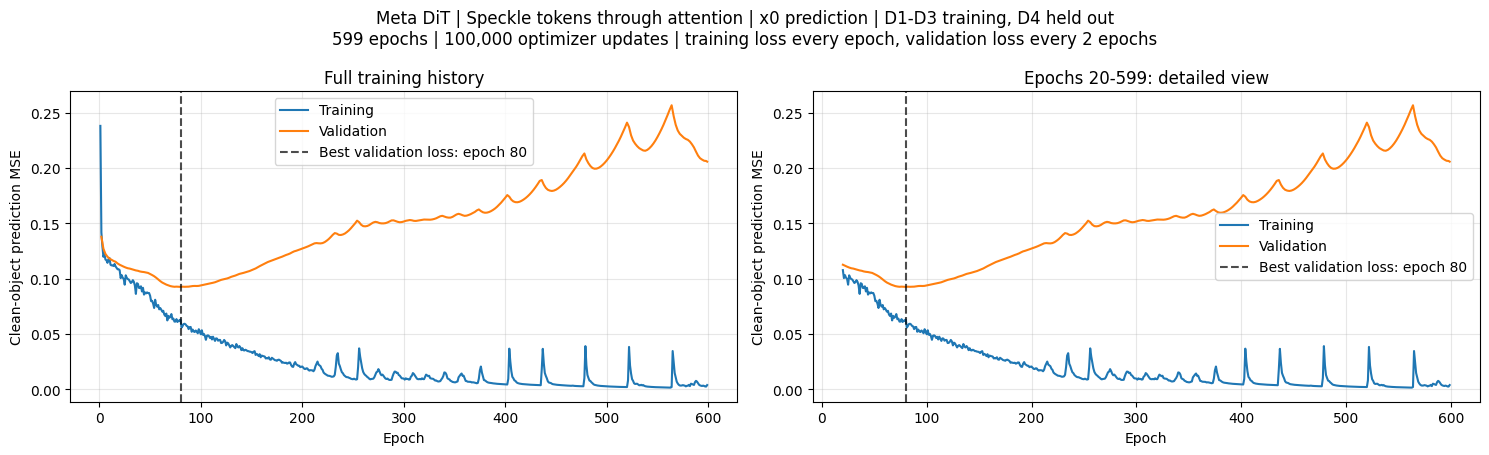

  Step  Epoch  TRAIN_x0_MSE  VAL_single_step_MSE  VAL_DDIM_PSNR  VAL_DDIM_SSIM  VAL_DDIM_Dice  VAL_DDIM_PCC
 10000     60       0.07340              0.09792        9.71881        0.75121        0.46775       0.41007
 20000    120       0.04396              0.09888       10.13821        0.77291        0.50195       0.44954
 30000    180       0.02557              0.11977       10.49255        0.77403        0.52398       0.47384
 40000    240       0.01686              0.13990       10.54743        0.78062        0.52374       0.47543
 50000    300       0.01002              0.15159       10.54726        0.78198        0.51962       0.47144
 60000    360       0.01274              0.15702       10.59998        0.78782        0.52212       0.47502
 70000    420       0.00464              0.17234       10.52933        0.79403        0.50725       0.45907
 80000    480       0.01773              0.21014       10.63241        0.79217        0.51442       0.46748
 90000    539       0.00288 

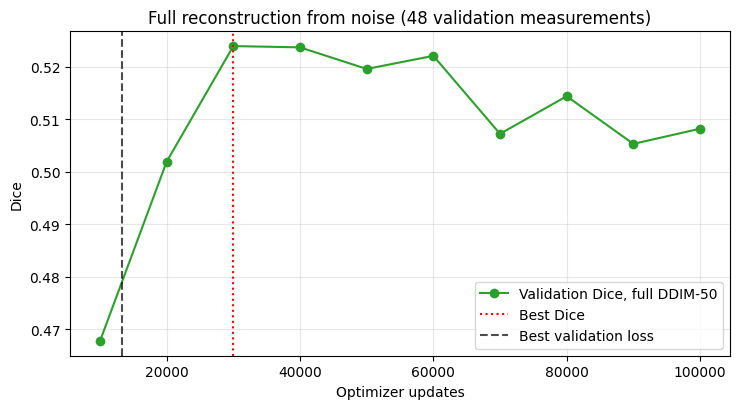

In [ ]:
#@title 12. Loss history per epoch and validation Dice of the full reconstruction
if not EPOCH_CSV.is_file() or not len(pd.read_csv(EPOCH_CSV)):
    print('No epoch history recorded yet.')
else:
    ep = pd.read_csv(EPOCH_CSV); val = ep.dropna(subset=['VAL_x0_MSE'])
    best_epoch = int(val.loc[val.VAL_x0_MSE.idxmin(), 'Epoch']); last_epoch = int(ep.Epoch.max())
    detail_from = 20 if last_epoch > 40 else 1
    fig, axs = plt.subplots(1, 2, figsize=(15, 4.6))
    for ax, first, title in ((axs[0], 1, 'Full training history'),
                             (axs[1], detail_from, 'Epochs %d-%d: detailed view' % (detail_from, last_epoch))):
        a = ep[ep.Epoch >= first]; b = val[val.Epoch >= first]
        ax.plot(a.Epoch, a.TRAIN_x0_MSE, label='Training')
        ax.plot(b.Epoch, b.VAL_x0_MSE, label='Validation')
        ax.axvline(best_epoch, color='k', ls='--', alpha=.7, label='Best validation loss: epoch %d' % best_epoch)
        ax.set(title=title, xlabel='Epoch', ylabel='Clean-object prediction MSE'); ax.grid(alpha=.3); ax.legend()
    fig.suptitle('Meta DiT | Speckle tokens through attention | x0 prediction | D1-D3 training, D4 held out\n'
                 '%d epochs | %s optimizer updates | training loss every epoch, validation loss every %d epochs' % (
                     last_epoch, format(int(ep.Step.max()), ','), VAL_LOSS_EVERY_EPOCHS))
    plt.tight_layout(); fig.savefig(RESULTS_DIR / 'loss_history.png', dpi=130, bbox_inches='tight'); plt.show(); plt.close(fig)
    if HISTORY_CSV.is_file() and len(pd.read_csv(HISTORY_CSV)):
        table = pd.read_csv(HISTORY_CSV)
        print(table.round(5).to_string(index=False))
        fig, ax = plt.subplots(figsize=(7.5, 4.2))
        ax.plot(table.Step, table.VAL_DDIM_Dice, marker='o', color='tab:green', label='Validation Dice, full DDIM-%d' % SAMPLE_STEPS)
        ax.axvline(int(table.loc[table.VAL_DDIM_Dice.idxmax(), 'Step']), color='r', ls=':', label='Best Dice')
        ax.axvline(best_epoch * STEPS_PER_EPOCH, color='k', ls='--', alpha=.7, label='Best validation loss')
        ax.set(title='Full reconstruction from noise (%d validation measurements)' % len(eval_ids), xlabel='Optimizer updates', ylabel='Dice')
        ax.grid(alpha=.3); ax.legend()
        plt.tight_layout(); fig.savefig(RESULTS_DIR / 'dice_history.png', dpi=130, bbox_inches='tight'); plt.show(); plt.close(fig)

## The unseen diffuser

The 60 sealed evaluation objects were not used for training or for choosing a checkpoint. Each is
reconstructed twice: from its Speckle through D1 (a diffuser seen in training) and through D4 (never seen).
The difference between the two rows is the price of the new diffuser.

Targets identical through D1 and D4: True
D1_known | Best loss checkpoint | step 13,360 (epoch 80) | 60 sealed objects | DDIM-50
PSNR   : 10.050107 +- 2.177375
SSIM   : 0.774949 +- 0.074081
Dice   : 0.479606 +- 0.152206
PCC    : 0.429229 +- 0.175936
MSE    : 0.110198 +- 0.046627
MSE_x0 : 0.440794 +- 0.186509

D4_unseen | Best loss checkpoint | step 13,360 (epoch 80) | 60 sealed objects | DDIM-50
PSNR   : 9.601545 +- 1.996962
SSIM   : 0.766534 +- 0.077540
Dice   : 0.419877 +- 0.128357
PCC    : 0.362925 +- 0.150338
MSE    : 0.120485 +- 0.049238
MSE_x0 : 0.481940 +- 0.196951

D1_known | Best Dice checkpoint | step 30,000 (epoch 180) | 60 sealed objects | DDIM-50
PSNR   : 10.508484 +- 2.271760
SSIM   : 0.781366 +- 0.067320
Dice   : 0.524244 +- 0.162019
PCC    : 0.478660 +- 0.187595
MSE    : 0.100355 +- 0.046199
MSE_x0 : 0.401421 +- 0.184794

D4_unseen | Best Dice checkpoint | step 30,000 (epoch 180) | 60 sealed objects | DDIM-50
PSNR   : 9.833382 +- 2.039407
SSIM   : 0.767244 +- 0.069448
D

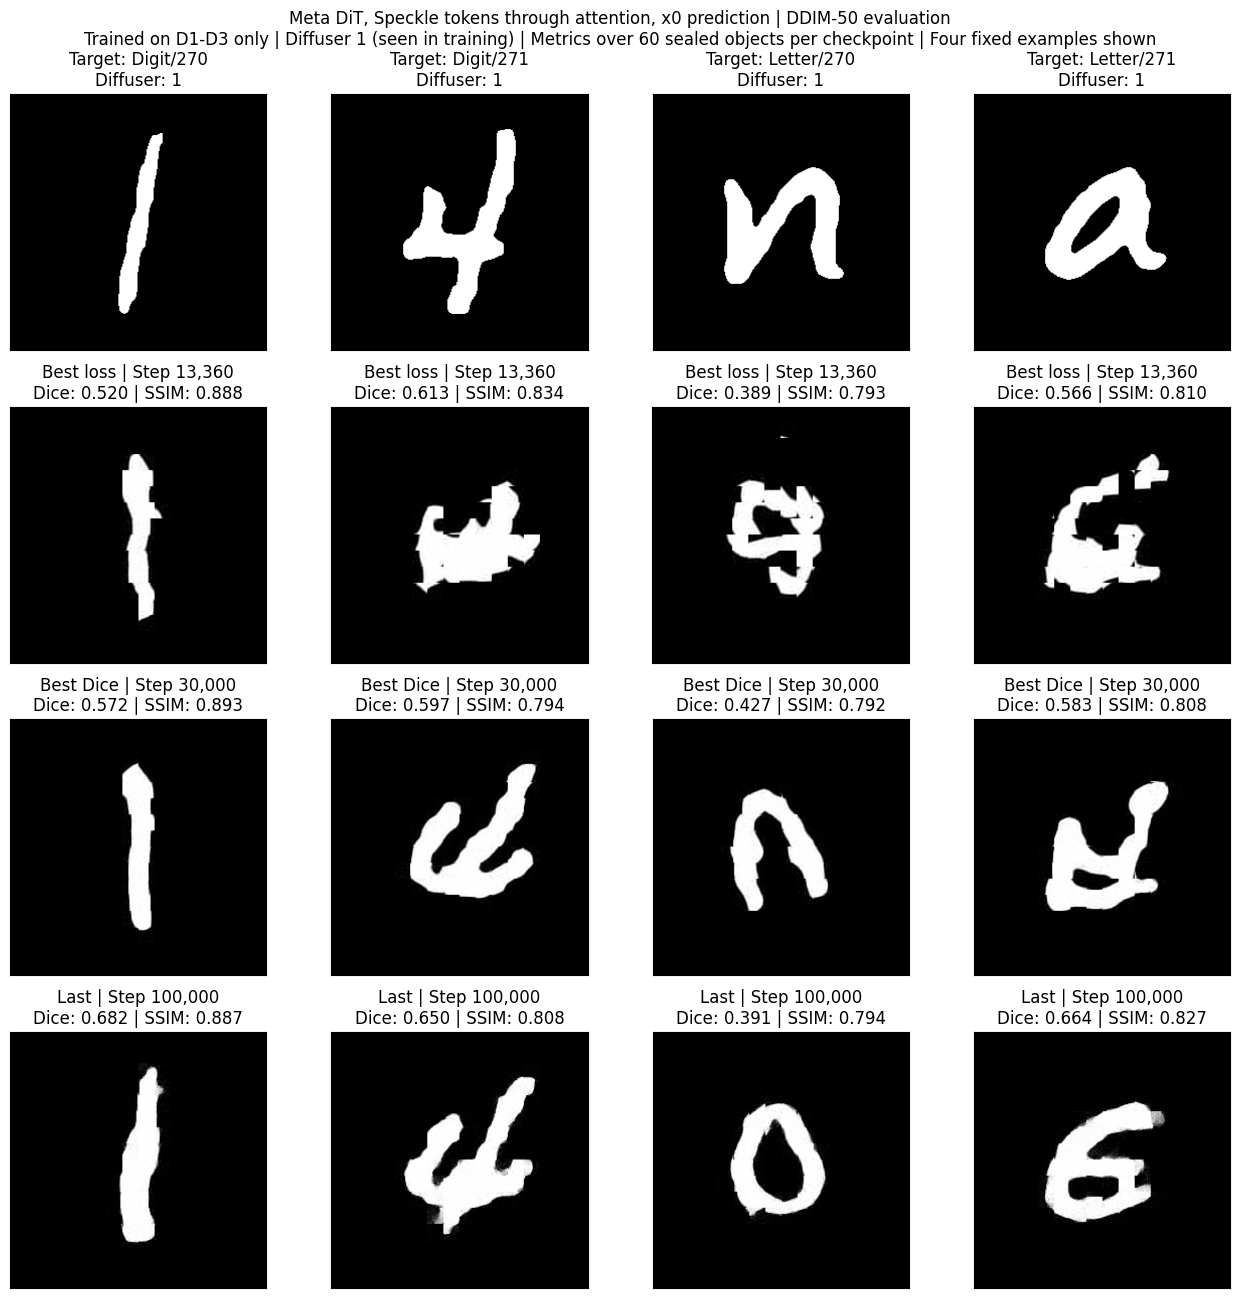

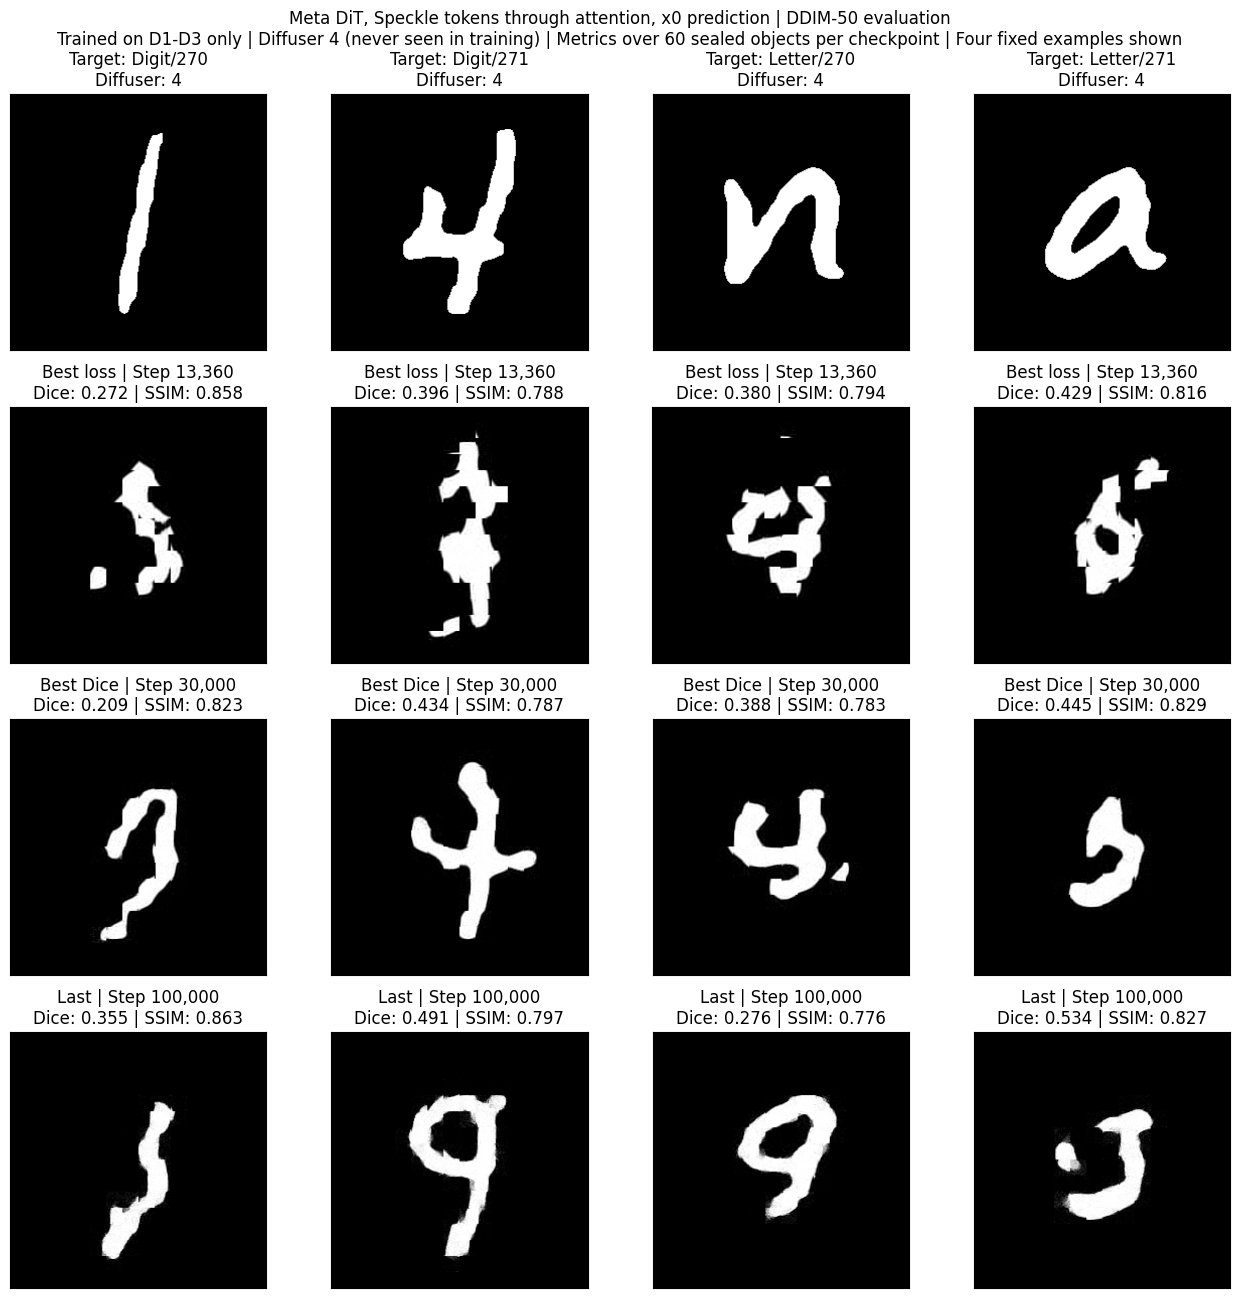

Saved to /content/drive/MyDrive/Speckle_Project/DiT_Pixel_X0_SpeckleTokens_D4HeldOut


In [ ]:
#@title 13. 60 sealed evaluation objects through D1 (known) and D4 (unseen): metrics, swap test, four fixed examples
if not RUN_D4_EVAL:
    print('SKIPPED: RUN_D4_EVAL=False. No D4 image was opened in this notebook.')
else:
    eval_keys = list(splits['EVAL'])
    eval_names = ['%s/%s' % (FAMILY_LABEL.get(k[0], k[0]), k[1]) for k in eval_keys]
    eval_family = [FAMILY_LABEL.get(k[0], k[0]) for k in eval_keys]
    def load_eval(d):
        with ThreadPoolExecutor(max_workers=16) as pool:
            loaded = list(pool.map(load_pair, [(complete[k][d]['speckle_path'], complete[k][d]['gt_path']) for k in eval_keys]))
        return torch.from_numpy(np.stack([a for a, _ in loaded])), torch.from_numpy(np.stack([b for _, b in loaded]))
    eval_sets = {'D1_known': load_eval('1'), 'D4_unseen': load_eval(HELDOUT_DIFFUSER)}
    print('Targets identical through D1 and D4:', bool(torch.equal(eval_sets['D1_known'][1], eval_sets['D4_unseen'][1])))
    fixed_keys = [('big', '270'), ('big', '271'), ('standard', '270'), ('standard', '271')]     # the four examples of the shared reports
    fixed = [eval_keys.index(k) for k in fixed_keys if k in eval_keys]
    if len(fixed) != 4:
        fixed = np.linspace(0, len(eval_keys) - 1, 4, dtype=int).tolist()
    ids = list(range(len(eval_keys)))
    eval_net = copy.deepcopy(ema).eval()
    d4_rows = []; shown = {}; frames = {}
    for kind in CHECKPOINT_KINDS:
        ckpt = load_checkpoint(kind); eval_net.load_state_dict(ckpt['ema'], strict=True)
        for label, (Xe, Me) in eval_sets.items():
            frame, pred, truth = evaluate(eval_net, Xe, Me, ids, seed=SEED + 21)     # same starting noise everywhere
            frame['MSE_x0'] = 4 * frame['MSE']
            frame.insert(1, 'Name', eval_names); frame.insert(2, 'Family', eval_family)
            frame.to_csv(RESULTS_DIR / f'eval60_{label}_{kind}_metrics.csv', index=False)
            d4_rows += summary_rows(frame, kind, ckpt, extra=dict(evaluation_set=label))
            shown[(kind, label)] = (ckpt, frame.iloc[fixed], pred[fixed]); frames[(kind, label)] = frame
            print_block('%s | %s checkpoint | step %s (epoch %d) | %d sealed objects | DDIM-%d' % (
                label, CHECKPOINT_LABEL[kind], format(ckpt['step'], ','), ckpt['epoch'], len(frame), SAMPLE_STEPS), frame)
    pd.DataFrame(d4_rows).to_csv(RESULTS_DIR / 'summary_metrics_D1_vs_D4.csv', index=False)
    truth_all = (2.0 * eval_sets['D1_known'][1].float() - 1.0)[:, None]
    blank = pd.DataFrame([im_metrics(-np.ones((256, 256), np.float32), truth_all[i].numpy()) for i in ids])
    print('Blank (all-black) image: PSNR %.4f | SSIM %.4f | Dice %.4f' % (blank.PSNR.mean(), blank.SSIM.mean(), blank.Dice.mean()))
    for label in eval_sets:
        print('Best-Dice checkpoint,', label, 'by family:')
        print(frames[('best_dice', label)].groupby('Family')[['Dice', 'PSNR', 'SSIM', 'PCC']].agg(['mean', 'std', 'count']).round(4).to_string())
    eval_net.load_state_dict(load_checkpoint('best_dice')['ema'], strict=True)
    swap_rows = {}
    for label, (Xe, Me) in eval_sets.items():
        swap_rows[label], _, _ = swap_test(eval_net, Xe, Me, ids, seed=SEED + 22)
    print('SPECKLE-SWAP TEST on the 60 sealed objects, best-Dice checkpoint:')
    print(pd.DataFrame(swap_rows).round(5).to_string())
    pd.DataFrame(swap_rows).to_csv(RESULTS_DIR / 'eval60_swap_test.csv')
    for label, (Xe, Me) in eval_sets.items():
        fig, axs = plt.subplots(1 + len(CHECKPOINT_KINDS), 4, figsize=(13, 3.3 * (1 + len(CHECKPOINT_KINDS))), squeeze=False)
        for j, i in enumerate(fixed):
            axs[0, j].imshow(Me[i].numpy(), cmap='gray', vmin=0, vmax=1)
            axs[0, j].set_title('Target: %s\nDiffuser: %s' % (eval_names[i], label[1]))
        for r, kind in enumerate(CHECKPOINT_KINDS, start=1):
            ckpt, part, pred = shown[(kind, label)]
            for j in range(4):
                axs[r, j].imshow((pred[j, 0].numpy() + 1) / 2, cmap='gray', vmin=0, vmax=1)
                axs[r, j].set_title('%s | Step %s\nDice: %.3f | SSIM: %.3f' % (
                    CHECKPOINT_LABEL[kind], format(ckpt['step'], ','), part.Dice.iloc[j], part.SSIM.iloc[j]))
        for a in axs.ravel(): a.set_xticks([]); a.set_yticks([])
        fig.suptitle('Meta DiT, Speckle tokens through attention, x0 prediction | DDIM-%d evaluation\n'
                     'Trained on D1-D3 only | %s | Metrics over %d sealed objects per checkpoint | Four fixed examples shown' % (
                         SAMPLE_STEPS, 'Diffuser 1 (seen in training)' if label == 'D1_known' else 'Diffuser 4 (never seen in training)', len(ids)))
        plt.tight_layout(); fig.savefig(RESULTS_DIR / f'four_fixed_examples_{label}.png', dpi=130, bbox_inches='tight')
        plt.show(); plt.close(fig)
    print('Saved to', RESULTS_DIR)

In [ ]:
#@title 14. Copy the report files to the shared report folder
REPORT_DIR.mkdir(parents=True, exist_ok=True)
report_files = ['summary_metrics.csv', 'summary_metrics_D1_vs_D4.csv', 'loss_history.png', 'dice_history.png',
                'four_fixed_examples_D1_known.png', 'four_fixed_examples_D4_unseen.png', 'validation_examples.png',
                'sanity_4_pairs.png', 'epoch_history.csv', 'history.csv']
for name in report_files:
    source_file = RESULTS_DIR / name
    if source_file.is_file():
        shutil.copyfile(source_file, REPORT_DIR / (REPORT_PREFIX + name))
        print('copied', REPORT_PREFIX + name)
    else:
        print('not found (cell not run yet?):', name)

copied dir1_D4heldout_summary_metrics.csv
copied dir1_D4heldout_summary_metrics_D1_vs_D4.csv
copied dir1_D4heldout_loss_history.png
copied dir1_D4heldout_dice_history.png
copied dir1_D4heldout_four_fixed_examples_D1_known.png
copied dir1_D4heldout_four_fixed_examples_D4_unseen.png
copied dir1_D4heldout_validation_examples.png
copied dir1_D4heldout_sanity_4_pairs.png
copied dir1_D4heldout_epoch_history.csv
copied dir1_D4heldout_history.csv


## Reading the results

- **Three checkpoints.** "Best loss" is the EMA with the lowest validation loss (a single denoising step).
  "Best Dice" is the EMA with the best full DDIM reconstruction on a fixed validation subset. "Last" is
  the EMA after the final update. All three are chosen or fixed without D4 and without the 60 evaluation objects.
- **Speckle-swap test:** with the same noise, the correct Speckle must give a clearly better reconstruction
  than the Speckle of another object. This is the direct check that the measurement is used.
- **D1 against D4** on the same 60 objects is the measure of generalisation to a new diffuser.
- **"Blank image"** is an all-black output. A model that is not clearly above it has not learned to reconstruct.
- This run is directly comparable with the contrastive-encoder notebook (same split, same evaluation
  objects, same sampler). It is **not** directly comparable with runs trained on all four diffusers.